## Mechanical validity


In [12]:
ROOT = "../outputs/results"
import pandas as pd
from results_loader import MODELS, load_all, task_thresholds, asr_found, intent_hit
import paper_tables as pt
asr2, intent2 = load_all(ROOT)
thr2 = task_thresholds(asr2, intent2)
print("m-valid UTMOS thresholds per task:", {t: round(v, 3) for t, v in thr2.items()})

METHODS_TAB = ["GATAS", "GATAS_llm", "Waveform", "SMACK_untargeted", "SMACK", "ALIF", "PGD"]
rows = []
for task, data, found in (("ASR", asr2, asr_found), ("Intent", intent2, intent_hit)):
    for model in MODELS:
        for m in METHODS_TAB:
            rs = data[model].get(m)
            if rs:
                f = [r for r in rs if found(r)]
                k = sum(r["utmos"] >= thr2[task] for r in f)
                rows.append({"task": task, "model": model, "method": m, "n": len(rs), "found": len(f), "m_valid": k,
                             "m_valid_of_found_%": 100 * k / len(f) if f else float("nan")})
frame = pd.DataFrame(rows)
frame.round(3).to_csv("_tables/rq3_values.csv", index=False)
display(frame.round(1))

def validity_cell(task, model, m):
    r = frame[(frame.task == task) & (frame.model == model) & (frame.method == m)]
    return f"{r['m_valid_of_found_%'].iloc[0]:.1f} ({r.m_valid.iloc[0]}/{r.found.iloc[0]})" if len(r) and r.found.iloc[0] else "--"

rows = []
for m in METHODS_TAB:
    cells = [validity_cell(task, model, m) for model in MODELS for task in ("ASR", "Intent")]
    rows.append(f"{pt.TEX_NAME[m]} & " + " & ".join(cells) + r" & \todo{} & \todo{} \\")
tex = "\n".join([
    r"\begin{table*}[t]",
    r"\caption{Validity (RQ\textsubscript{3}). Share of m-valid test cases among the found ones (ASR) / target hits (intent), counts in parentheses. \todo{human MOS}}",
    r"\label{tab:validity}", r"\centering", r"\footnotesize", r"\adjustbox{max width=\textwidth}{%",
    r"\begin{tabular}{lcccccc}\toprule",
    r" & \multicolumn{2}{c}{Whisper-tiny} & \multicolumn{2}{c}{wav2vec2-large} & \multicolumn{2}{c}{Human MOS (Whisper-tiny)} \\",
    r"\cmidrule(lr){2-3}\cmidrule(lr){4-5}\cmidrule(lr){6-7}",
    r" & ASR [\%] & Intent [\%] & ASR [\%] & Intent [\%] & Technical & Semantic \\ \midrule",
    *rows, r"\bottomrule", r"\end{tabular}}", r"\end{table*}"])
print(tex)
import os; os.makedirs("_tables", exist_ok=True); open("_tables/rq3.tex", "w").write(tex + "\n")


m-valid UTMOS thresholds per task: {'ASR': 4.262, 'Intent': 4.031}


/home/weissl/Projects/GATAS/analysis/results_loader.py:32: UserWarning: No PGD results for harvard / wav2vec2-large in ../outputs/results
  warnings.warn(f"No {method} results for {dataset} / {asr_model} in {results_root}")
/home/weissl/Projects/GATAS/analysis/results_loader.py:32: UserWarning: No PGD results for commands / wav2vec2-large in ../outputs/results
  warnings.warn(f"No {method} results for {dataset} / {asr_model} in {results_root}")


,task,model,method,n,found,m_valid,m_valid_of_found_%
0,ASR,whisper-tiny,GATAS,71,63,37,58.7
1,ASR,whisper-tiny,Waveform,71,71,0,0.0
2,ASR,whisper-tiny,SMACK_untargeted,72,65,1,1.5
3,ASR,whisper-tiny,SMACK,72,50,2,4.0
4,ASR,whisper-tiny,ALIF,72,72,0,0.0
5,ASR,whisper-tiny,PGD,72,72,0,0.0
6,ASR,wav2vec2-large,GATAS,92,86,50,58.1
7,ASR,wav2vec2-large,Waveform,92,92,0,0.0
8,ASR,wav2vec2-large,SMACK_untargeted,92,78,5,6.4
9,ASR,wav2vec2-large,SMACK,92,68,1,1.5


\begin{table*}[t]
\caption{Validity (RQ\textsubscript{3}). Share of m-valid test cases among the found ones (ASR) / target hits (intent), counts in parentheses. \todo{human MOS}}
\label{tab:validity}
\centering
\footnotesize
\adjustbox{max width=\textwidth}{%
\begin{tabular}{lcccccc}\toprule
 & \multicolumn{2}{c}{Whisper-tiny} & \multicolumn{2}{c}{wav2vec2-large} & \multicolumn{2}{c}{Human MOS (Whisper-tiny)} \\
\cmidrule(lr){2-3}\cmidrule(lr){4-5}\cmidrule(lr){6-7}
 & ASR [\%] & Intent [\%] & ASR [\%] & Intent [\%] & Technical & Semantic \\ \midrule
\tool & 58.7 (37/63) & 44.4 (4/9) & 58.1 (50/86) & -- & \todo{} & \todo{} \\
\gllm & -- & 76.4 (55/72) & -- & 72.0 (18/25) & \todo{} & \todo{} \\
\wv & 0.0 (0/71) & 0.0 (0/20) & 0.0 (0/92) & 0.0 (0/11) & \todo{} & \todo{} \\
\smack$^\ddagger$ & 1.5 (1/65) & -- & 6.4 (5/78) & -- & \todo{} & \todo{} \\
\smack & 4.0 (2/50) & 0.0 (0/6) & 1.5 (1/68) & 0.0 (0/1) & \todo{} & \todo{} \\
\alif & 0.0 (0/72) & 0.0 (0/36) & 0.0 (0/92) & 0.0 (0/14) & \

1124

## Human study: data and exclusions


In [13]:
import json, os, urllib.request
import numpy as np
from scipy import stats
from stats_utils import wilson_ci

SHEET = "1gqpJs8xKk-GUQ6TEnX8SrmjrWkQGdU6OqM8bKmMDTWk"
RESPONSES = "../survey/responses.csv"
ATTENTION = 75  # min. share [%] of clean recordings that must be heard as the shown text
try:
    urllib.request.urlretrieve(f"https://docs.google.com/spreadsheets/d/{SHEET}/export?format=csv", RESPONSES)
except Exception:
    print("sheet not reachable, using the cached", RESPONSES)
raw = pd.read_csv(RESPONSES)
key = json.load(open("../survey/private/key.json"))

def item_row(item):
    k = key[item]
    task = "ASR" if k["cell"].endswith("asr") else "Intent"
    ev = json.load(open(os.path.join("..", os.path.dirname(k["source"]), "evaluation.json")))
    clean = k["condition"] == "clean"
    method = "Clean" if clean else {"ours": "GATAS" if task == "ASR" else "GATAS_llm"}.get(k["condition"], k["condition"])
    return {"item": item, "task": task, "model": ev["asr_model"], "method": method,
            "utmos": ev["scores"]["UTMOS_ORIGINAL" if clean else "UTMOS"]}

items = pd.DataFrame([item_row(i) for i in key]).set_index("item")
items["m_valid"] = items.utmos >= items.task.map(thr2)
d = raw.join(items, on="item")

participants = d.groupby("participant").apply(lambda g: pd.Series({
    "ratings": len(g), "distinct items": g.item.nunique(),
    "clean heard as shown [%]": 100 * (g[g.method == "Clean"].understood_match == "yes").mean(),
    "clean transcript plausible [%]": 100 * (g[g.method == "Clean"].plausible_transcription == "yes").mean(),
    "not played": int((g.plays < 1).sum()), "median seconds": g.seconds.median(), "realism sd": g.realism.std()}), include_groups=False)
participants["valid"] = (participants["clean heard as shown [%]"] >= ATTENTION) & (participants["distinct items"] == participants.ratings)
ok = d[d.participant.isin(participants.index[participants.valid]) & (d.plays >= 1)]
print(f"valid participants: {participants.valid.sum()} of {len(participants)}; ratings kept: {len(ok)} of {len(d)}; "
      f"audios rated: {ok.item.nunique()} of {len(items)}")

valid participants: 3 of 3; ratings kept: 96 of 96; audios rated: 93 of 542


## Realism


In [18]:
def boot_spearman(x, y, n_boot=5000, seed=0):
    rng = np.random.default_rng(seed)
    b = []
    for _ in range(n_boot):
        j = rng.integers(0, len(x), len(x))
        if np.ptp(x[j]) and np.ptp(y[j]):
            b.append(stats.spearmanr(x[j], y[j])[0])
    return np.quantile(b, [0.025, 0.975])

def rho(df, col):
    x, y = df[col].to_numpy(float), df.realism.to_numpy(float)
    if len(df) < 3 or not np.ptp(x):
        return np.nan, np.nan, np.nan
    return (stats.spearmanr(x, y)[0], *boot_spearman(x, y))

per_audio = ok.groupby("item").agg(realism=("realism", "mean")).join(items)
rows = []
for task, model in [(t, m) for t in ("ASR", "Intent") for m in MODELS] + [("all", "all")]:
    df = per_audio[((per_audio.task == task) | (task == "all")) & ((per_audio.model == model) | (model == "all"))]
    row = {"task": task, "model": model, "audios": len(df)}
    for name, col in (("UTMOS", "utmos"), ("m-valid", "m_valid")):
        r, *_ = rho(df, col)
        row.update({f"{name} rho": r})
    rows.append(row)
realism = pd.DataFrame(rows)
realism.round(2).to_csv("_tables/rq3_human_realism.csv", index=False)
display(realism.round(2))

,task,model,audios,UTMOS rho,m-valid rho
0,ASR,whisper-tiny,23,0.66,0.55
1,ASR,wav2vec2-large,24,0.84,0.73
2,Intent,whisper-tiny,23,0.87,0.78
3,Intent,wav2vec2-large,23,0.74,0.55
4,all,all,93,0.80,0.61


## Human validity


In [19]:
import matplotlib.pyplot as plt
from results_loader import tex_name

ORDER = ["Clean", "GATAS", "GATAS_llm", "SMACK", "ALIF"]
ANSWERS = ["yes", "unsure", "no"]
rows = []
for (task, method), g in ok.groupby(["task", "method"]):
    n, k = len(g), int((g.understood_match == "yes").sum())
    rows.append({"task": task, "method": method, "ratings": n,
                 **{a: 100 * (g.understood_match == a).mean() for a in ANSWERS},
                 "strict [%]": 100 * k / n,
                 "lenient [%]": 100 * (g.understood_match != "no").mean()})
validity = pd.DataFrame(rows).sort_values(["task", "method"], key=lambda s: s.map(ORDER.index) if s.name == "method" else s)
validity.round(1).to_csv("_tables/rq3_human_validity.csv", index=False)
display(validity.round(1))

,task,method,ratings,yes,unsure,no,strict [%],lenient [%]
1,ASR,Clean,12,100.0,0.0,0.0,100.0,100.0
2,ASR,GATAS,12,66.7,33.3,0.0,66.7,100.0
3,ASR,SMACK,12,25.0,8.3,66.7,25.0,33.3
0,ASR,ALIF,12,25.0,16.7,58.3,25.0,41.7
5,Intent,Clean,12,100.0,0.0,0.0,100.0,100.0
6,Intent,GATAS_llm,12,8.3,16.7,75.0,8.3,25.0
7,Intent,SMACK,12,8.3,8.3,83.3,8.3,16.7
4,Intent,ALIF,12,16.7,0.0,83.3,16.7,16.7


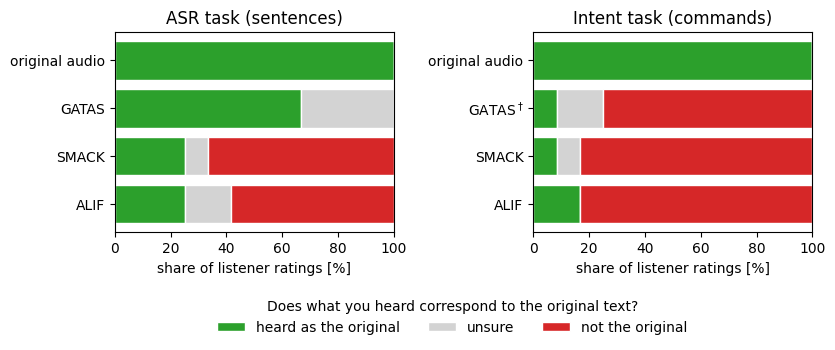

In [16]:
COLORS = {"yes": "tab:green", "unsure": "lightgray", "no": "tab:red"}
LEGEND = {"yes": "heard as the original", "unsure": "unsure", "no": "not the original"}
NAMES = {"Clean": "original audio", "GATAS": "GATAS", "GATAS_llm": "GATAS$^\\dagger$", "SMACK": "SMACK", "ALIF": "ALIF"}
fig, axes = plt.subplots(1, 2, figsize=(9, 2.6), sharex=True, gridspec_kw={"wspace": 0.5})
for ax, task, title in zip(axes, ("ASR", "Intent"), ("ASR task (sentences)", "Intent task (commands)")):
    v = validity[validity.task == task].reset_index(drop=True)
    left = np.zeros(len(v))
    for a in ANSWERS:
        ax.barh(range(len(v)), v[a], left=left, color=COLORS[a], label=LEGEND[a], edgecolor="white")
        left += v[a].to_numpy()
    ax.set_yticks(range(len(v))); ax.set_yticklabels([NAMES[m] for m in v.method]); ax.invert_yaxis()
    ax.set_xlim(0, 100); ax.set_xlabel("share of listener ratings [%]"); ax.set_title(title)
fig.legend(*axes[0].get_legend_handles_labels(), ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False,
           title="Does what you heard correspond to the original text?")
plt.savefig("_figures/rq3_human_validity.pdf", bbox_inches="tight")

In [17]:
def cell(task, m):
    r = validity[(validity.task == task) & (validity.method == m)]
    return f"{r['strict [%]'].iloc[0]:.0f}--{r['lenient [%]'].iloc[0]:.0f}" if len(r) else "--"

lines = [r"\begin{tabular}{lcc}\toprule", r" & ASR [\%] & Intent [\%] \\ \midrule"]
lines += [f"{'Clean' if m == 'Clean' else tex_name(m)} & {cell('ASR', m)} & {cell('Intent', m)} \\\\" for m in ORDER]
lines += [r"\bottomrule", r"\end{tabular}"]
open("_tables/rq3_human_validity.tex", "w").write("\n".join(lines) + "\n")
print(open("_tables/rq3_human_validity.tex").read())

\begin{tabular}{lcc}\toprule
 & ASR [\%] & Intent [\%] \\ \midrule
Clean & 100--100 & 100--100 \\
\textsc{Gatas} & 67--100 & -- \\
\textsc{Gatas}\textsuperscript{$\dagger$} & -- & 8--25 \\
\textsc{Smack} & 25--33 & 8--17 \\
\textsc{Alif} & 25--42 & 17--17 \\
\bottomrule
\end{tabular}

